# 9.2 Coding Practice: LSTM Sentiment Classification (Solution)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/obscrivn/mynewbook/blob/master/module9/week09_lstm_practice_solution.ipynb)

**Solution.** Completed TODOs, suggested answers, and notes on the outputs observed when this notebook was tested. Try the practice notebook first, then compare.

This guided practice follows the Week 09 reading, *From RNNs and LSTMs to Language Models* (Chapter 9 of the course book). You will turn short movie reviews into ordered sequences of numbers, run a small PyTorch LSTM that reads them one token at a time, and test whether word order changes its predictions.

The running example from the reading returns here:

> *Everyone told me the film was boring, but I loved it.*

Each part follows the same rhythm: a short explanation, a question to predict or interpret, a small piece of code to run or complete, and a look at the output. The whole notebook runs on a CPU in Google Colab in under a minute of compute time. Plan for about 30 to 45 minutes.

This is ungraded practice. There is nothing to submit.

## Learning goals

- Convert tokenized text into numerical sequences.
- Explain the roles of embeddings and LSTM hidden states.
- Run a simple PyTorch LSTM sentiment classifier.
- Interpret predictions and identify model limitations.
- Compare sequence modeling with the TF-IDF classification you used earlier in the course.

## Setup

Everything this notebook needs (`torch`, `pandas`, `scikit-learn`, `matplotlib`) is already installed in Google Colab, so there is nothing to install. The default CPU runtime is enough; you do not need a GPU.

The next cell fixes the random seeds. Neural networks start from random weights, and fixing the seed makes your run repeatable. Small differences between PyTorch versions can still change the exact numbers slightly. Focus on patterns, not on matching every decimal.

In [1]:
import random
import re
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)  # keeps CPU results repeatable

print("PyTorch version:", torch.__version__)

PyTorch version: 2.14.0


## 1. From text to sequences

The dataset below is a set of 40 short movie reviews written for this practice: 20 positive (label `1`) and 20 negative (label `0`). It is deliberately tiny so that training takes seconds. Many reviews come in mirrored pairs that use similar words with the opposite meaning, for example *"the ending was not bad"* (positive) and *"the ending was not great"* (negative). Several use negation (*not*, *never*) or contrast (*but*), the same patterns that broke word-counting in Week 07.

A separate set of 8 test reviews is kept aside. The model never trains on them, so they give a first, very small check of whether it learned anything beyond the training sentences.

In [2]:
train_data = [
    # positive (1)
    ("the acting was great", 1),
    ("i loved the ending", 1),
    ("the music was beautiful", 1),
    ("a wonderful and fun film", 1),
    ("the story was good", 1),
    ("the plot was not boring", 1),
    ("the ending was not bad", 1),
    ("the film was not dull at all", 1),
    ("the plot was slow but i loved it", 1),
    ("the first hour was dull but the ending was great", 1),
    ("critics said it was boring but i enjoyed it", 1),
    ("the cast was bad but the story was wonderful", 1),
    ("some scenes were slow but the music was beautiful", 1),
    ("i expected to hate it but it was fun", 1),
    ("everyone said the plot was awful but i loved it", 1),
    ("not a bad film at all", 1),
    ("the acting was good not bad", 1),
    ("i enjoyed every scene", 1),
    ("the movie was fun and the cast was great", 1),
    ("it was never boring", 1),
    # negative (0)
    ("the acting was awful", 0),
    ("i hated the ending", 0),
    ("the music was dull", 0),
    ("a boring and slow film", 0),
    ("the story was bad", 0),
    ("the plot was not good", 0),
    ("the ending was not great", 0),
    ("the film was not fun at all", 0),
    ("the music was beautiful but the plot was boring", 0),
    ("the first hour was fun but the ending was awful", 0),
    ("critics said it was great but i hated it", 0),
    ("the cast was good but the story was dull", 0),
    ("some scenes were fun but the film was slow", 0),
    ("i expected to love it but it was boring", 0),
    ("everyone said the plot was wonderful but i hated it", 0),
    ("not a good film at all", 0),
    ("the acting was bad not good", 0),
    ("i hated every scene", 0),
    ("the movie was dull and the cast was awful", 0),
    ("it was never fun", 0),
]

test_data = [
    ("the ending was slow but the acting was great", 1),
    ("the story was not dull", 1),
    ("critics said it was slow but i loved the music", 1),
    ("the film was not awful", 1),
    ("the acting was great but the ending was dull", 0),
    ("the story was not wonderful", 0),
    ("critics said it was fun but i hated the plot", 0),
    ("the movie was not good at all", 0),
]

train_df = pd.DataFrame(train_data, columns=["text", "label"])
print(train_df["label"].value_counts().rename({1: "positive", 0: "negative"}))
train_df.sample(6, random_state=SEED)

label
positive    20
negative    20
Name: count, dtype: int64


,text,label
19,it was never boring,1
16,the acting was good not bad,1
15,not a bad film at all,1
26,the ending was not great,0
4,the story was good,1
12,some scenes were slow but the music was beautiful,1


### Predict before coding

Look at the mirrored pair *"the plot was slow but i loved it"* (positive) and *"the music was beautiful but the plot was boring"* (negative). Both contain one positive and one negative word. Which part of each sentence decides the label? Would a model that only counts words be able to tell?

### TODO 1: Build a vocabulary and convert words to IDs

A neural network works with numbers, so each word needs an integer ID. We reserve two special IDs:

- `0` for `<pad>`, a filler token used to make sentences the same length (TODO 2).
- `1` for `<unk>`, used for any word the model never saw in training.

The `tokenize` function is provided. Complete the two marked lines.

In [3]:
def tokenize(text):
    return re.findall(r"[a-z]+", text.lower())


vocab = {"<pad>": 0, "<unk>": 1}
for text, _ in train_data:
    for token in tokenize(text):
        if token not in vocab:
            vocab[token] = len(vocab)


def encode(text):
    return [vocab.get(token, vocab["<unk>"]) for token in tokenize(text)]


print("Vocabulary size:", len(vocab))
print(encode("the plot was slow but i loved it"))

Vocabulary size: 48
[2, 18, 4, 25, 26, 6, 7, 27]


Now encode the running example from the reading. Some of its words never appear in the training reviews. Look for the `<unk>` ID (`1`) in the output.

In [4]:
running_example = "Everyone told me the film was boring, but I loved it."
ids = encode(running_example)
id_to_token = {i: t for t, i in vocab.items()}

print(ids)
print([id_to_token[i] for i in ids])

[40, 1, 1, 2, 15, 4, 20, 26, 6, 7, 27]
['everyone', '<unk>', '<unk>', 'the', 'film', 'was', 'boring', 'but', 'i', 'loved', 'it']


### TODO 2: Pad sequences to the same length

PyTorch processes several sentences at once as a single tensor (a batch), which must be rectangular. Shorter sentences are filled with the `<pad>` ID.

We put the padding **before** the words (left padding). The LSTM reads left to right, so this way the last step it reads is always a real word. Its final hidden state then summarizes the actual sentence, as in the reading's classifier diagram. (Larger projects often use a PyTorch feature called packed sequences instead. Left padding keeps this notebook simple.)

In [5]:
def pad_batch(id_lists):
    max_len = max(len(ids) for ids in id_lists)
    padded = []
    for ids in id_lists:
        padded.append([vocab["<pad>"]] * (max_len - len(ids)) + ids)
    return torch.tensor(padded, dtype=torch.long)


X_train = pad_batch([encode(text) for text, _ in train_data])
y_train = torch.tensor([label for _, label in train_data], dtype=torch.long)

print("X_train shape:", tuple(X_train.shape), " (sentences, tokens per sentence)")
print("y_train shape:", tuple(y_train.shape))
print("First two padded rows:")
print(X_train[:2])

X_train shape: (40, 10)  (sentences, tokens per sentence)
y_train shape: (40,)
First two padded rows:
tensor([[0, 0, 0, 0, 0, 0, 2, 3, 4, 5],
        [0, 0, 0, 0, 0, 0, 6, 7, 2, 8]])


Compare two reviews with exactly the same words in a different order, using the two representations side by side.

In [6]:
a = "i loved it but the plot was slow"
b = "the plot was slow but i loved it"

print("Bag of words equal?  ", Counter(tokenize(a)) == Counter(tokenize(b)))
print("ID sequences equal?  ", encode(a) == encode(b))
print(encode(a))
print(encode(b))

Bag of words equal?   True
ID sequences equal?   False
[6, 7, 27, 26, 2, 18, 4, 25]
[2, 18, 4, 25, 26, 6, 7, 27]


**Guided question 1:** The two reviews above have identical bags of words but different ID sequences. What information does the sequence keep that the bag of words throws away? Why might that matter for sentiment?

**Suggested answer:** The sequence keeps position. In the first review the positive clause comes first and *slow* comes last; in the second, *i loved it* comes last. In this dataset the clause after *but* usually carries the writer's own verdict, so order is real evidence about sentiment. A bag of words treats the two reviews as identical and cannot use that evidence.

## 2. Understanding the LSTM model

The model below has the three layers described in Section 5 of the reading:

1. **Embedding layer.** Turns each word ID into a short learned vector (here, 16 numbers). Words used in similar ways tend to end up with similar vectors during training.
2. **LSTM layer.** Reads the embeddings one time step at a time and carries a hidden state forward. Its gates decide what to keep, add, or reveal. You do not need to implement them; PyTorch's `nn.LSTM` does that.
3. **Linear layer.** Takes the LSTM's **final hidden state** and produces two scores, one for negative and one for positive.

Read the class, then complete TODO 3.

In [7]:
class SentimentLSTM(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, num_classes=2):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True)
        self.classifier = nn.Linear(hidden_dim, num_classes)

    def forward(self, x):
        embedded = self.embedding(x)              # (batch, tokens, embed_dim)
        outputs, (h_n, c_n) = self.lstm(embedded)  # h_n: (1, batch, hidden_dim)
        final_hidden = h_n[-1]                    # (batch, hidden_dim)
        return self.classifier(final_hidden)      # (batch, 2) scores

### TODO 3: Create the model and trace tensor shapes

Create the model with the sizes given, then pass four training reviews through it one layer at a time.

**Predict first:** for a batch of 4 padded reviews, each `T` tokens long, what shape will the embedding output have? What shape will the final hidden state have? Write your guesses, then run the cell.

In [8]:
EMBED_DIM = 16
HIDDEN_DIM = 32

torch.manual_seed(SEED)
model = SentimentLSTM(len(vocab), EMBED_DIM, HIDDEN_DIM)

sample = X_train[:4]
embedded = model.embedding(sample)
outputs, (h_n, c_n) = model.lstm(embedded)

print("input IDs:        ", tuple(sample.shape))
print("embeddings:       ", tuple(embedded.shape))
print("LSTM outputs:     ", tuple(outputs.shape), " (one hidden state per time step)")
print("final hidden h_n: ", tuple(h_n.shape))
print("cell state c_n:   ", tuple(c_n.shape))
print("class scores:     ", tuple(model(sample).shape))
print("Trainable parameters:", sum(p.numel() for p in model.parameters()))

input IDs:         (4, 10)
embeddings:        (4, 10, 16)
LSTM outputs:      (4, 10, 32)  (one hidden state per time step)
final hidden h_n:  (1, 4, 32)
cell state c_n:    (1, 4, 32)
class scores:      (4, 2)
Trainable parameters: 7234


**Guided question 2:** The LSTM outputs one hidden state per time step, but the classifier uses only the final one, `h_n`, which always has 32 numbers no matter how long the review is. What does that final hidden state represent? What might be lost when a long review has to fit into it?

**Suggested answer:** `h_n` is a 32-number summary of the whole review as the LSTM read it from left to right. Training shapes it to keep whatever helps predict the label. Its size is fixed, so a 5-word review and a 500-word review get the same amount of space. Early words reach it only through every later step, so in a long review early information can fade or be overwritten, and the model may lean on the most recent words (reading, Section 4).

## 3. Train and predict

Training repeats three steps: score the training reviews, measure the error with a loss function, and nudge every weight to reduce that error. PyTorch computes the nudges with backpropagation through time, which the reading describes in Section 3. The loop below is complete. Run it and watch the loss.

Because the dataset is tiny, the whole training set is used at every step, and 150 steps take only a few seconds.

epoch   1  loss 0.6971
epoch  25  loss 0.0165
epoch  50  loss 0.0004


epoch 100  loss 0.0001
epoch 150  loss 0.0001


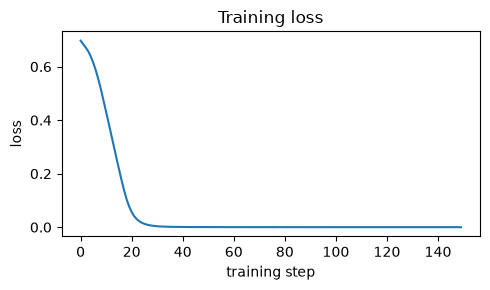

In [9]:
torch.manual_seed(SEED)
model = SentimentLSTM(len(vocab), EMBED_DIM, HIDDEN_DIM)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

losses = []
for epoch in range(1, 151):
    model.train()
    optimizer.zero_grad()
    loss = loss_fn(model(X_train), y_train)
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
    if epoch in (1, 25, 50, 100, 150):
        print(f"epoch {epoch:3d}  loss {loss.item():.4f}")

plt.figure(figsize=(5, 3))
plt.plot(losses)
plt.xlabel("training step")
plt.ylabel("loss")
plt.title("Training loss")
plt.tight_layout()
plt.show()

### TODO 4: Turn scores into probabilities

The model outputs two raw scores per review. As in Week 05, a softmax turns scores into probabilities that add up to 1. Complete the line in `predict_proba`, then check accuracy on the training and test reviews.

In [10]:
def predict_proba(texts):
    model.eval()
    with torch.no_grad():
        scores = model(pad_batch([encode(t) for t in texts]))
        probs = torch.softmax(scores, dim=1)
    return probs[:, 1].numpy()  # probability of "positive"


def accuracy(data):
    p_pos = predict_proba([text for text, _ in data])
    preds = (p_pos >= 0.5).astype(int)
    labels = np.array([label for _, label in data])
    return (preds == labels).mean(), p_pos


train_acc, _ = accuracy(train_data)
test_acc, test_p = accuracy(test_data)
print(f"Training accuracy: {train_acc:.2f}")
print(f"Test accuracy:     {test_acc:.2f}  (only {len(test_data)} reviews)")

pd.DataFrame({
    "text": [t for t, _ in test_data],
    "true label": [l for _, l in test_data],
    "P(positive)": test_p.round(3),
})

Training accuracy: 1.00
Test accuracy:     0.62  (only 8 reviews)


,text,true label,P(positive)
0,the ending was slow but the acting was great,1,1.000
1,the story was not dull,1,0.004
2,critics said it was slow but i loved the music,1,1.000
3,the film was not awful,1,0.001
4,the acting was great but the ending was dull,0,0.009
5,the story was not wonderful,0,0.724
6,critics said it was fun but i hated the plot,0,0.000
7,the movie was not good at all,0,0.419


**Guided question 3:** Training accuracy is probably perfect or close to it. What does that tell you, and what does it *not* tell you? Why is accuracy on 8 test reviews weak evidence either way?

**Suggested answer:** Perfect training accuracy, with loss near 0.0001, shows that the model can fit these 40 reviews, possibly by memorizing them. It does not show that the model generalizes. In our verification run (PyTorch 2.14, CPU) test accuracy was 0.62, or 5 of 8. The model misclassified *the story was not dull* and *the film was not awful* as negative, and gave *the story was not wonderful* a 0.724 probability of being positive. With 8 reviews, each one moves accuracy by 12.5 percentage points, and the set covers only a few patterns. Notice also that the probabilities are close to 0 or 1 even when the answer is wrong (0.004 for *the story was not dull*). A confident probability is not evidence of a correct prediction.

## 4. Experiment with word order

Now test the model on reviews it has never seen, chosen to probe order, negation, and contrast. Two come from the reading.

**Predict before running.** For each review below, write down whether you expect the model to say positive or negative, and how confident it will be.

| Review | Your prediction |
|---|---|
| everyone told me the film was boring but i loved it | |
| i loved it but everyone told me the film was boring | |
| the music was good not bad | |
| the music was bad not good | |
| the film was good | |
| the film was not good | |
| i loved it even though the plot was slow and the music was dull | |

Treat surprises as useful evidence, not as mistakes on your part. The model has seen only 40 reviews.

In [11]:
experiments = [
    "everyone told me the film was boring but i loved it",
    "i loved it but everyone told me the film was boring",
    "the music was good not bad",
    "the music was bad not good",
    "the film was good",
    "the film was not good",
    "i loved it even though the plot was slow and the music was dull",
]

results = pd.DataFrame({
    "review": experiments,
    "P(positive)": predict_proba(experiments).round(3),
    "unknown words": [
        [t for t in tokenize(s) if t not in vocab] for s in experiments
    ],
})
results

,review,P(positive),unknown words
0,everyone told me the film was boring but i lov...,1.000,"[told, me]"
1,i loved it but everyone told me the film was b...,0.000,"[told, me]"
2,the music was good not bad,1.000,[]
3,the music was bad not good,0.001,[]
4,the film was good,1.000,[]
5,the film was not good,0.000,[]
6,i loved it even though the plot was slow and t...,0.000,"[even, though]"


### TODO 5: Write your own test reviews

Write two short reviews of your own. Try one that should stay positive when you reorder it and one where reordering should flip the meaning. Use words from the training vocabulary where you can; the cell lists any unknown words, which the model sees only as `<unk>`.

In [12]:
my_reviews = [
    "the plot was dull but the acting was great",
    "the acting was great but the plot was dull",
]

pd.DataFrame({
    "review": my_reviews,
    "P(positive)": predict_proba(my_reviews).round(3),
    "unknown words": [[t for t in tokenize(s) if t not in vocab] for s in my_reviews],
})

,review,P(positive),unknown words
0,the plot was dull but the acting was great,1.0,[]
1,the acting was great but the plot was dull,0.0,[]


**Guided question 4:** Look across your experiments.

- Does changing word order change the prediction?
- Does the model handle negation correctly in the examples you tried?
- What limitations do you notice? Think about the unknown words, the size of the training set, and the longer review that puts the writer's verdict first.

**Suggested answer:** Observed in our verification run (PyTorch 2.14, CPU); your exact numbers may differ slightly.

- **Order matters to this model.** The running example scored 1.000 while its reordered version scored 0.000. *the music was good not bad* scored 1.000 and *the music was bad not good* 0.001. The two TODO 5 reviews flipped from 1.0 to 0.0 when reordered.
- **Negation is handled only partly.** The model was right on *the film was not good* (0.000) and on the *good not bad* pair, which closely mirror training sentences. It failed on the Part 3 test reviews *not dull*, *not awful*, and *not wonderful*. It learned negation for the adjectives it saw negated in training (*not boring*, *not bad*, *not good*), not a general rule that *not* flips the next word.
- **It learned a shortcut.** Contrast reviews in training put the verdict after *but*, so the model learned roughly that the last clause decides. *i loved it even though the plot was slow and the music was dull* scored 0.000 even though the writer loved the film. This is the long-distance case from the reading.
- **Unknown words and data size.** *told*, *me*, *even*, and *though* are all `<unk>`, so the model cannot use them. Forty reviews are far too few for real sentiment analysis, and the near-certain probabilities show overconfidence rather than understanding.

## 5. Connecting the dots

In Weeks 05 and 07 you classified text with TF-IDF features and logistic regression. The next cell trains that kind of classifier on the same 40 reviews and scores two reviews that use exactly the same words in a different order.

In [13]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

tfidf = TfidfVectorizer()
X_tfidf = tfidf.fit_transform([text for text, _ in train_data])
tfidf_clf = LogisticRegression(max_iter=1000).fit(X_tfidf, [label for _, label in train_data])

pair = ["i loved it but the plot was slow", "the plot was slow but i loved it"]
tfidf_p = tfidf_clf.predict_proba(tfidf.transform(pair))[:, 1]

pd.DataFrame({
    "review": pair,
    "TF-IDF P(positive)": tfidf_p.round(3),
    "LSTM P(positive)": predict_proba(pair).round(3),
})

,review,TF-IDF P(positive),LSTM P(positive)
0,i loved it but the plot was slow,0.59,0.312
1,the plot was slow but i loved it,0.59,1.000


| Approach | Text representation | Word order |
|---|---|---|
| TF-IDF classifier | Sparse document vector | Not explicitly represented |
| LSTM classifier | Ordered token embeddings | Processed sequentially |

The TF-IDF classifier gives the two reviews identical probabilities, because their unigram TF-IDF vectors are identical. The LSTM reads them in order and can give different answers, though whether its answers are *better* depends on what it learned from very little data.

### Reflection

1. When might an LSTM be more appropriate than a TF-IDF classifier? When might TF-IDF still be the better first choice?
2. Why might sequential processing become challenging for longer texts?

**Suggested answers:**

1. An LSTM is worth considering when order and composition carry the meaning (negation, contrast, sequence labeling) and there is enough labeled data to learn those patterns. TF-IDF with logistic regression remains a strong first choice when word presence is enough, data is limited, speed matters, or you need to explain decisions by inspecting weights. In this notebook, neither model is reliable: the LSTM fit the training reviews perfectly but learned shortcuts.
2. The LSTM reads one token at a time, so it cannot process positions in parallel and slows down on long texts. Everything it has read must pass through a fixed-size hidden state, so early information can fade, and learning connections across many steps is harder even with gates. These are the limitations that attention and transformers address in Week 10.

### Looking ahead to Week 10

The LSTM squeezes everything it has read into one fixed-size hidden state and has to read one token at a time. In Week 10, **attention** lets a model look back at every earlier position directly, and **transformers** build on attention to train on far more text. BERT and transfer learning follow from there.

## Validation checks

These checks confirm that the notebook ran top to bottom without hidden state. If one fails, rerun the notebook from the top (Runtime > Restart and run all in Colab).

In [14]:
assert vocab["<pad>"] == 0 and vocab["<unk>"] == 1
assert X_train.shape[0] == len(train_data) == 40
assert (X_train[:, -1] != vocab["<pad>"]).all(), "Left padding: the last token should be a real word."
assert model(X_train[:3]).shape == (3, 2)
assert losses[-1] < losses[0], "Training loss should go down."
assert np.allclose(tfidf_p[0], tfidf_p[1]), "TF-IDF ignores order, so these should match."
p = predict_proba(["the film was good"])
assert 0.0 <= p[0] <= 1.0
print("All checks passed.")

All checks passed.
